<center>
<h1><b> TP3: Prompt Engineering </b>
<h1><b>Classification tasks : Sentiment Analysis </b>
</center>

**Étudiant :** ELAALGI Hatim — Module Système Distribué Agentique, Master S3

# Objectives

- Present LLMs as an effective tool to tackle classification problems.
- Illustrate prompt engineering for sentiment analysis.
- Build and evaluate LLMs on broader classification tasks.

## Mes choix pour ce TP

| Élément | Notebook / PDF du prof | Ce notebook |
|---|---|---|
| Tokens | `tiktoken`, encodage `o200k_base` | identique |
| Appel LLM | OpenAI `gpt-4o`, ou Ollama `qwen3.5:cloud` | **Groq** (API gratuite) : `qwen/qwen3.8-27b`, de la même famille Qwen que le modèle Ollama du prof |
| Données | IMDB (Hugging Face) | `dataset_imdb.zip` fourni (50 000 critiques) |
| Gold examples | 20, `random_state=42`, découpage 80 / 20 | identique |
| Few-shot | 4 positifs + 4 négatifs mélangés | identique |
| Évaluation | micro-F1, 10 répétitions | identique, sur **deux modèles** : un petit (`allam-2-7b`, 7 milliards de paramètres) et un plus grand (`qwen/qwen3.8-27b`) |

Pourquoi deux modèles ? Dans le PDF, `gpt-5.2` obtient 1.0 avec les trois prompts : un modèle aussi fort ne permet pas de voir ce qu'apportent le few-shot et le CoT. Avec un petit modèle, l'effet du prompt devient mesurable.

La clé est lue dans le fichier `.env` à la racine du dépôt (`GROQ_API_KEY=...`), qui n'est pas versionné.

# Preparer l'environement

1. Prendre VS Code, je vais créer un un nouveau dossier que je vais appeler **SMA_TokPr** et ouvrir le terminal.
2. **UV** install: utiliser la la commande, pour MacOS: ```curl -LsSf https://astral.sh/uv/install.sh | sh```  sous Windows utiliser la commande dans le powerShell: `powershell -ExecutionPolicy ByPass -c "irm https://astral.sh/uv/install.ps1 | iex"`. Après instalation de UV quittez et relancez VScode.
3. dans le terminal de VsCode utiliser la commande ` uv init ` pour initialiser le projet. Donc ça nous permet de générer la structure des projets notamment avec le fichier **.toml** .
4. créer un environnement virtuel. Avec la commande: ` uv venv ` .
3. autoriser PowerSell à exécuter les scripts avec cette commande dans le terminal: ` Set-ExecutionPolicy -ExecutionPolicy RemoteSigned -Scope Process ` . puis aller au dosssier **Scripts** et activer les scripts avec la commande:  ` .\.venv\Scripts\activate `.
5.  cree un notebook **prompttoken.ipynb** pour le test puis choisir un noyaux(le kernel) et tester avec `print("Bonjour")` .

7. installer la bib tiktoken avec ` uv add tiktoken `

> **Dans mon dépôt**, l'environnement uv est celui du conteneur Docker du TP0. J'ai ajouté les dépendances du TP3 au même projet (`uv add tiktoken langchain langchain-groq python-dotenv scikit-learn tqdm`), puis reconstruit l'image (`docker compose build`). Le kernel **Python (uv-env)** du conteneur exécute ce notebook.

In [1]:
print("Bonjour")

Bonjour


# Partie 1 — Les tokens

In [2]:
import tiktoken

In [3]:
tokenizer=tiktoken.encoding_for_model("gpt-4o")

In [4]:
print(tokenizer.name)

o200k_base


In [5]:
tokenizer=tiktoken.get_encoding("o200k_base")

In [6]:
prompt="Vous êtes un expert en marketing digital. C'est quoi un digital marketer ? "

In [7]:
tokens=tokenizer.encode(prompt)

In [8]:
print(tokens)

[29038, 34077, 537, 8333, 469, 6686, 7058, 13, 363, 6616, 33399, 537, 7058, 95641, 1423, 220]


In [9]:
print(len(tokens))

16


In [10]:
for token in tokens:
    t=tokenizer.decode_single_token_bytes(token).decode("utf-8")
    print(t,end='|')

Vous| êtes| un| expert| en| marketing| digital|.| C|'est| quoi| un| digital| marketer| ?| |

**Ce qu'on observe.** Le tokeniseur ne découpe ni par lettre ni par mot : il découpe en **morceaux fréquents** de son vocabulaire (`o200k_base`, environ 200 000 entrées, celui de GPT-4o). L'espace est collé au début du mot suivant (`| expert`), et la ponctuation forme ses propres tokens. Le modèle ne voit que la liste d'entiers : c'est elle qu'il faut compter pour estimer le coût d'un appel et vérifier qu'un prompt tient dans la fenêtre de contexte.

**Test personnel : la même phrase en français, en anglais et en arabe.**

In [11]:
phrases = {
    "français": "Je suis étudiant en master d'intelligence artificielle à Tanger.",
    "anglais": "I am a master's student in artificial intelligence in Tangier.",
    "arabe": "أنا طالب ماستر في الذكاء الاصطناعي في طنجة.",
}
for langue, phrase in phrases.items():
    ids = tokenizer.encode(phrase)
    morceaux = [tokenizer.decode_single_token_bytes(t).decode("utf-8", errors="replace") for t in ids]
    print(f"{langue:<9} {len(phrase.split()):>2} mots -> {len(ids):>2} tokens : {'|'.join(morceaux)}")

français   9 mots -> 13 tokens : Je| suis| étudiant| en| master| d|'int|elligence| artific|ielle| à| Tanger|.
anglais   10 mots -> 12 tokens : I| am| a| master's| student| in| artificial| intelligence| in| Tang|ier|.
arabe      8 mots -> 16 tokens : أنا| طالب| ما|ستر| في| الذ|ك|اء| الاص|ط|نا|عي| في| طن|جة|.


**Ce qu'on observe.** Pour la même phrase, l'anglais donne **12 tokens** pour 10 mots, le français **13 tokens** pour 9 mots et l'arabe **16 tokens** pour 8 mots. Le vocabulaire de `o200k_base` contient surtout des morceaux de mots anglais : « intelligence » est un seul token en anglais, mais « d'intelligence » devient `d|'int|elligence` et « artificielle » devient `artific|ielle`. En arabe, presque chaque mot est coupé en 2 ou 3 morceaux (`الاص|ط|نا|عي`). À contenu égal, un prompt en arabe ou en français **coûte donc plus cher** et occupe plus de place dans la fenêtre de contexte qu'un prompt en anglais. C'est une raison pour laquelle les prompts du TP sont écrits en anglais.

# Utilisation des llm

8. installer la dépendance langchain avec la commande: ` uv add langchain ` et installer langchain-openai ` uv add langchain-openai `

**Code du prof (OpenAI)**, que je remplace par Groq :
```python
from langchain_openai import ChatOpenAI
llm=ChatOpenAI(model="gpt-4o", temperature=0)
```
Avec LangChain, changer de fournisseur revient à changer de classe : `ChatGroq` (paquet `langchain-groq`) a la même interface que `ChatOpenAI`.

In [12]:
import os
from dotenv import load_dotenv
from langchain_groq import ChatGroq
from IPython.display import Markdown, display

load_dotenv(override=True)   # cherche le fichier .env en remontant les dossiers
print("GROQ_API_KEY trouvée :", bool(os.getenv("GROQ_API_KEY")))

GROQ_API_KEY trouvée : True


In [13]:
llm = ChatGroq(model="qwen/qwen3.8-27b", temperature=0)

**apel** a llm

In [14]:
resp=llm.invoke(input=[{"role":"system","content":"Vous êtes un expert en marketing digital"},{"role":"user","content":"C'est quoi un digital marketer ?"}])

In [15]:
display(Markdown(resp.content))

En tant qu'expert en marketing digital, je vais vous donner une définition claire et structurée.

Un **digital marketer** (ou marketeur digital) est un professionnel qui conçoit, met en œuvre et optimise des stratégies de marketing utilisant les canaux numériques pour atteindre, engager et convertir une audience cible.

Contrairement au marketing traditionnel (TV, radio, presse papier), le digital marketer travaille principalement sur des supports en ligne et utilise des données pour mesurer et améliorer la performance en temps réel.

### Les missions principales d'un digital marketer :

1. **Stratégie et planification** :
   - Définir les objectifs (notoriété, génération de leads, ventes, fidélisation).
   - Identifier la cible (personas).
   - Choisir les canaux les plus pertinents (SEO, réseaux sociaux, email, display, etc.).

2. **Création de contenu (Content Marketing)** :
   - Rédiger des articles de blog, des newsletters, des posts pour les réseaux sociaux.
   - Produire ou superviser la création de vidéos, infographies, podcasts.
   - Adapter le message à chaque canal.

3. **Acquisition de trafic et de leads** :
   - **SEO (Search Engine Optimization)** : Optimiser le site web pour qu’il apparaisse en tête des résultats de Google.
   - **SEA (Search Engine Advertising)** : Gérer les campagnes publicitaires payantes (Google Ads, Bing Ads).
   - **Social Media Marketing** : Gérer les communautés et les campagnes sponsorisées sur LinkedIn, Instagram, Facebook, TikTok, etc.
   - **Email Marketing** : Automatiser et personnaliser les envois d’emails.

4. **Analyse et optimisation** :
   - Utiliser des outils comme Google Analytics, GA4, Hotjar, ou des tableaux de bord (Power BI, Looker Studio).
   - Mesurer les KPIs (Key Performance Indicators) : taux de clic (CTR), coût par acquisition (CPA), taux de conversion, ROI.
   - Ajuster les campagnes en continu pour améliorer les résultats (A/B testing).

5. **Expérience utilisateur (UX) et conversion** :
   - Collaborer avec les équipes techniques et design pour s’assurer que le site web est facile à utiliser et orienté vers la conversion.

### Compétences clés :

- **Techniques** : Maîtrise des outils (Google Ads, Meta Business Suite, HubSpot, Mailchimp, WordPress, etc.).
- **Analytiques** : Capacité à interpréter les données et à prendre des décisions basées sur les faits.
- **Créatives** : Sensibilité pour le storytelling et la création de contenu engageant.
- **Stratégiques** : Vision globale du parcours client (customer journey).
- **Adaptabilité** : Le digital évolue très vite (nouvelles plateformes, algorithmes, tendances), il faut être en veille permanente.

### En résumé :

Un digital marketer est un **pont entre la marque et le consommateur** dans l’espace numérique. Son rôle est de maximiser la visibilité, l’engagement et les revenus d’une entreprise grâce à l’utilisation intelligente des technologies et des données.

Souhaitez-vous que je détaille un aspect spécifique (comme le SEO, les réseaux sociaux ou l’email marketing) ?

In [16]:
# Ce que l'appel a coûté, en tokens (lien avec la partie 1)
usage = resp.response_metadata["token_usage"]
print("tokens du prompt :", usage["prompt_tokens"], "| tokens de la réponse :", usage["completion_tokens"])
print("tiktoken (o200k_base) compte", len(tokenizer.encode("Vous êtes un expert en marketing digital" + "C'est quoi un digital marketer ?")),
      "tokens pour les deux messages")

tokens du prompt : 31 | tokens de la réponse : 714
tiktoken (o200k_base) compte 14 tokens pour les deux messages


**Remarques.**
- Le message `system` fixe le rôle (« expert en marketing digital ») et le message `user` porte la question. La réponse est un `AIMessage` dont le texte est dans `.content`.
- `temperature=0` choisit toujours le token le plus probable : la réponse est (presque) **déterministe**, ce dont on a besoin pour comparer des prompts dans la partie 3.
- Le nombre de tokens facturés par Groq est plus élevé que le compte de `tiktoken`, pour deux raisons : Qwen a **son propre tokeniseur**, et le modèle ajoute des tokens de formatage autour de chaque message (rôles, début et fin de message).
- Dans le notebook du prof, `print(display(...))` affiche aussi `None`, car `display()` ne renvoie rien. J'appelle donc `display()` seul.

# ollama llm

Le prof propose aussi un modèle via **Ollama** (`ollama run qwen3.5:cloud`, puis `uv add langchain-ollama`) :
```python
from langchain_ollama import ChatOllama
llm2=ChatOllama(model="qwen3.5:cloud", temperature=0)
resp2=llm2.invoke(input=[{"role":"system","content":"Vous êtes un expert en marketing digital"},{"role":"user","content":"C'est quoi un digital marketer ?"}])
```
Je n'ai pas installé Ollama sur ma machine : le modèle Qwen utilisé plus haut via Groq joue ce rôle. Le code est le même ; seule la classe change (`ChatOllama` au lieu de `ChatGroq`).

---
# Partie 2 — Use case : Sentiment Analysis

## Step 1 : Define Objectives and Metrics
Chaque critique de film reçoit l'une des deux étiquettes **positive** ou **negative**. On mesure :
- l'**accuracy** : la part de prédictions correctes ;
- le **micro-F1** : on additionne les TP, FP et FN de toutes les classes, puis on calcule $F_1 = \frac{2PR}{P+R}$.

Je refais le calcul de l'exemple du PDF (TP = 50, FP = 10, FN = 5, TN = 100) avec `sklearn` :

In [17]:
import numpy as np
from sklearn.metrics import f1_score, accuracy_score

# Matrice du PDF : 50 TP, 10 FP, 5 FN, 100 TN  ->  165 exemples
y_true = ["positive"] * 50 + ["negative"] * 10 + ["positive"] * 5 + ["negative"] * 100
y_pred = ["positive"] * 50 + ["positive"] * 10 + ["negative"] * 5 + ["negative"] * 100

print("F1 de la classe 'positive' :", round(f1_score(y_true, y_pred, pos_label="positive"), 3))
print("micro-F1 (2 classes)        :", round(f1_score(y_true, y_pred, average="micro"), 3))
print("accuracy                    :", round(accuracy_score(y_true, y_pred), 3))

F1 de la classe 'positive' : 0.87
micro-F1 (2 classes)        : 0.909
accuracy                    : 0.909


**Remarque sur l'exemple du PDF.** La valeur 0,870 du PDF est le F1 de la **seule classe positive** ($2 \cdot 50 / (2 \cdot 50 + 10 + 5)$). Le **micro-F1** sur les deux classes compte aussi les 100 négatifs bien classés comme vrais positifs de la classe *negative*. Il vaut 0,909, c'est-à-dire exactement l'accuracy (150 / 165). Ce n'est pas un hasard : quand chaque exemple reçoit **une seule** étiquette, chaque erreur compte une fois en FP (classe prédite) et une fois en FN (vraie classe), donc micro-précision = micro-rappel = accuracy. Dans la suite, `f1_score(..., average="micro")` est donc égal à l'accuracy, y compris quand le modèle répond `unknown`.

## Step 2 : Assemble Data
Le PDF charge IMDB avec `load_dataset("imdb")`. J'utilise l'archive `dataset_imdb.zip` fournie, que `pandas` lit directement sans la décompresser.

In [18]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.model_selection import train_test_split

train_df = pd.read_csv("dataset_imdb.zip")
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB


In [19]:
train_df.sentiment.value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

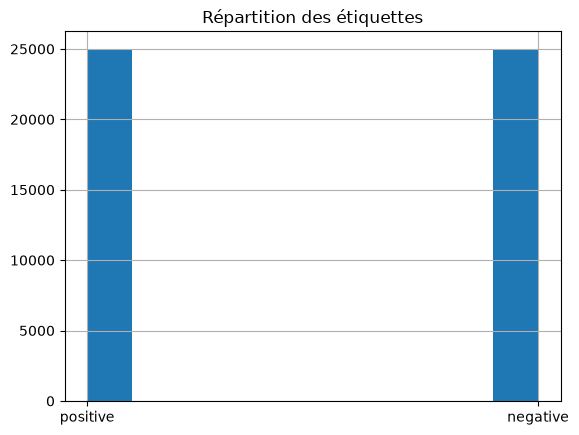

In [20]:
train_df.sentiment.hist()
plt.title("Répartition des étiquettes")
plt.show()

**Prétraitement.**
- La colonne texte s'appelle `review` : je la renomme `text`, comme dans le PDF.
- Le PDF ajoute `sentiment` à partir de `label`. Ici, c'est l'inverse : le CSV a déjà `sentiment`, et j'en déduis `label` (1 = positive).
- Je retire les balises `<br />` laissées par le scraping.
- **Je garde les critiques de 80 mots au plus.** C'est un écart par rapport au PDF, imposé par deux contraintes. `allam-2-7b` a une fenêtre de contexte de **4 096 tokens**, et un prompt few-shot contient 8 critiques en plus de la critique à classer : avec des critiques longues (jusqu'à 2 000 mots dans IMDB), il déborderait. De plus, l'offre gratuite de Groq limite les tokens par minute et par jour.

In [21]:
MAX_MOTS = 80

train_df = train_df.rename(columns={"review": "text"})
train_df["text"] = train_df["text"].str.replace(r"<br\s*/?>", " ", regex=True).str.strip()
train_df["label"] = np.where(train_df.sentiment == "positive", 1, 0)
train_df = train_df[train_df["text"].str.split().str.len() <= MAX_MOTS].reset_index(drop=True)

print(len(train_df), "critiques de", MAX_MOTS, "mots au plus")
print(train_df.sentiment.value_counts())
train_df.sample(6, random_state=7)

4217 critiques de 80 mots au plus
sentiment
positive    2352
negative    1865
Name: count, dtype: int64


,text,sentiment,label
3561,Pointless movie about making a movie. No where...,negative,0
2252,An excellent story well told by the film maker...,positive,1
3815,.....whoops - looks like it's gonna cost you a...,positive,1
578,Billy and Jade had a very close relationship t...,positive,1
370,A very courageous attempt to bring one of the ...,positive,1
3381,"This thing takes the horny teenager genre, ver...",negative,0


Découpage 80 % / 20 % : un réservoir d'**exemples** few-shot et un réservoir de **gold examples** pour l'évaluation (code du PDF).

In [22]:
examples_df, gold_examples_df = train_test_split(
    train_df, test_size=0.2, random_state=42
)
(examples_df.shape, gold_examples_df.shape)

((3373, 3), (844, 3))

In [23]:
columns= ['text', 'sentiment']
gold_examples = (
    gold_examples_df.loc[:, columns]
    .sample(20, random_state=42)
    .to_json(orient='records'))

# Le jeu curé est enregistré en JSON pour les itérations suivantes
os.makedirs("data", exist_ok=True)
with open("data/gold_examples.json", "w", encoding="utf-8") as f:
    f.write(gold_examples)

json.loads(gold_examples)[0]

{'text': "It's unbelievable but the fourth is better than the second and the third. After the third that was awful, it's incredible how they could have an unexpected sequel with new ideas. Chuck is the same nasty doll of the previous movies. Interesting the final that lets know that a fifth can be done....",
 'sentiment': 'positive'}

In [24]:
pd.Series([e["sentiment"] for e in json.loads(gold_examples)]).value_counts()

negative    11
positive     9
Name: count, dtype: int64

## Step 3 : Élaborer le prompt

### Prompt 1 : Zero-shot

In [25]:
zero_shot_system_message = """
Classify the sentiment of movie reviews presented in the input as 'positive' or 'negative'
Movie reviews will be delimited by triple backticks in the input.
Answer only 'positive' or 'negative'
Do not explain your answer.
"""

In [26]:
zero_shot_prompt = [{'role':'system', 'content': zero_shot_system_message}]

In [27]:
user_message_template = """```{movie_review}```"""

### Prompt 2 : Few-shot
Même message système, enrichi d'exemples. Pour éviter le **biais de l'étiquette majoritaire**, on prend autant de positifs que de négatifs ; pour éviter le **biais de récence**, on les mélange. J'ajoute un paramètre `random_state` à la fonction du PDF : chaque tirage reste aléatoire, mais il est reproductible d'une exécution à l'autre.

In [28]:
few_shot_system_message = """
Classify the sentiment of movie reviews presented in the input as 'positive' or 'negative'
Movie reviews will be delimited by triple backticks in the input.
Answer only 'positive' or 'negative'
Do not explain your answer.
"""


def create_examples(dataset, n=4, random_state=None):
    positive_reviews = (dataset.sentiment == 'positive')
    negative_reviews = (dataset.sentiment == 'negative')
    columns_to_select = ['text', 'sentiment']
    positive_examples = dataset.loc[positive_reviews, columns_to_select].sample(n, random_state=random_state)
    negative_examples = dataset.loc[negative_reviews, columns_to_select].sample(n, random_state=random_state)
    examples = pd.concat([positive_examples, negative_examples])
    # sampling without replacement is equivalent to random shuffling
    randomized_examples = examples.sample(2*n, replace=False, random_state=random_state)
    return randomized_examples.to_json(orient='records')


examples = create_examples(examples_df, 2, random_state=0)
json.loads(examples)

[{'text': 'I recently viewed this atrocity in my film program, and I thought it was awful, as I said in my tagline, it was pretentious, trite, petty and phenomenally self-important.  I consider myself a fan of film, and all the things that film has to offer. If I want to watch a documentary on the Cannes Festival, I will watch A&E....and they would probably be alot more objective about it.  I dont recommend it, period.',
  'sentiment': 'negative'},
 {'text': "The core message is strong, the cast has given it their best shot, the packaging is excellent, but the screenplay is seriously over-dramatized and every cliche in the book on women's suffering in India has been over-used to the max.",
  'sentiment': 'negative'},
 {'text': 'Drum scene is wild! Cook, Jr. is unsung hero of this and many movies. Fantastic actor, great flick. A few twists that keep you moving. A must-see.',
  'sentiment': 'positive'},
 {'text': "I had the pleasure of seeing Saltimbanco live before seeing the video vers

In [29]:
def create_prompt(system_message, examples, user_message_template):
    few_shot_prompt = [{'role':'system', 'content': system_message}]
    for example in json.loads(examples):
        example_review = example['text']
        example_sentiment = example['sentiment']
        few_shot_prompt.append(
            {'role': 'user', 'content': user_message_template.format(movie_review=example_review)}
        )
        few_shot_prompt.append(
            {'role': 'assistant', 'content': f"{example_sentiment}"}
        )
    return few_shot_prompt


examples = create_examples(examples_df, random_state=42)   # n=4 -> 8 exemples
few_shot_prompt = create_prompt(few_shot_system_message, examples, user_message_template)
[m["role"] for m in few_shot_prompt]

['system',
 'user',
 'assistant',
 'user',
 'assistant',
 'user',
 'assistant',
 'user',
 'assistant',
 'user',
 'assistant',
 'user',
 'assistant',
 'user',
 'assistant',
 'user',
 'assistant']

### Prompt 3 : Chain-of-Thought
Mêmes exemples, mais le message système ajoute des instructions étape par étape.

In [30]:
cot_system_message = """
Classify the sentiment of movie reviews presented in the input as 'positive' or 'negative'
Movie reviews will be delimited by triple backticks ``` in the input.
Answer only 'positive' or 'negative'
Do not explain your answer.

Instructions:
1. Carefully read the text of the review and think through the options for sentiment provided
2. Consider the overall sentiment of the review and estimate the probability of the review being positive

To reiterate, your answer should strictly only contain the label: positive or negative
"""

cot_few_shot_prompt = create_prompt(cot_system_message, examples, user_message_template)

Taille des trois prompts, mesurée avec `tiktoken` (partie 1), avant d'y ajouter la critique à classer :

In [31]:
def nb_tokens(messages):
    return sum(len(tokenizer.encode(m["content"])) for m in messages)

for nom, p in [("zero-shot", zero_shot_prompt), ("few-shot", few_shot_prompt), ("CoT few-shot", cot_few_shot_prompt)]:
    print(f"{nom:<13} {len(p):>2} messages, ~{nb_tokens(p)} tokens")

zero-shot      1 messages, ~49 tokens
few-shot      17 messages, ~663 tokens
CoT few-shot  17 messages, ~720 tokens


## Step 4 : Evaluate Prompts

### Les deux modèles évalués

In [32]:
petit_modele = ChatGroq(model="allam-2-7b", temperature=0, max_retries=0)
grand_modele = ChatGroq(model="qwen/qwen3.8-27b", temperature=0, max_retries=0)

**Appels à l'API.** L'évaluation complète représente environ 1 000 appels. Pour les rendre robustes, `appeler()` ajoute deux choses au simple `model.invoke()` :
- un **cache** sur disque (`data/cache_llm.json`) : une requête identique (même modèle, mêmes messages) n'est jamais envoyée deux fois. Si l'exécution est interrompue, elle reprend là où elle s'était arrêtée, et les résultats restent reproductibles sans clé ;
- une **attente** quand Groq répond « 429 : limite de tokens par minute atteinte » : on attend le délai indiqué par l'API, puis on réessaie. Si c'est le quota **journalier** qui est épuisé, on s'arrête avec un message clair ;
- de nouvelles tentatives en cas d'**erreur passagère** du serveur (erreur 5xx, surcharge). Lors d'une première exécution, quelques appels avaient échoué de cette façon et la critique était simplement sautée, ce qui faussait le score.

In [33]:
import hashlib
import time
from groq import RateLimitError, APIStatusError, APIConnectionError

CACHE_PATH = "data/cache_llm.json"
cache = json.load(open(CACHE_PATH, encoding="utf-8")) if os.path.exists(CACHE_PATH) else {}


class QuotaJournalierAtteint(Exception):
    pass


def appeler(model, messages):
    cle = hashlib.sha256(json.dumps([model.model_name, messages], ensure_ascii=False).encode()).hexdigest()
    if cle not in cache:
        for essai in range(20):
            try:
                cache[cle] = model.invoke(messages).content
                break
            except RateLimitError as e:
                attente = float(e.response.headers.get("retry-after", 10))
                if attente > 600:
                    raise QuotaJournalierAtteint(f"{model.model_name} : réessayer dans {attente / 3600:.1f} h") from e
                time.sleep(attente + 1)
            except (APIStatusError, APIConnectionError) as e:
                # erreur passagère du serveur (5xx, surcharge, coupure réseau) : on réessaie un peu plus tard
                if essai == 19 or (isinstance(e, APIStatusError) and e.status_code < 500):
                    raise
                time.sleep(min(5 * (essai + 1), 60))
        with open(CACHE_PATH, "w", encoding="utf-8") as f:
            json.dump(cache, f, ensure_ascii=False)
    return cache[cle]

`evaluate_prompt` est la fonction du PDF. Seul l'appel `model.invoke(prompt+user_input)` passe par `appeler()`. Je garde aussi les prédictions (`derniers_resultats`) pour pouvoir analyser les erreurs ensuite.

In [34]:
derniers_resultats = {}


def evaluate_prompt(prompt, gold_examples, user_message_template, model):
    model_predictions, ground_truths = [], []

    for example in json.loads(gold_examples):
        gold_input = example['text']
        user_input = [
            {
                'role':'user',
                'content': user_message_template.format(movie_review=gold_input)
            }
        ]
        try:
            response_content = appeler(model, prompt+user_input)
            if 'negative' in response_content.strip().lower():
                prediction='negative'
            elif 'positive' in response_content.strip().lower():
                prediction='positive'
            else:
                prediction ='unknown'
            model_predictions.append(prediction)
            ground_truths.append(example['sentiment'])
        except QuotaJournalierAtteint:
            raise
        except Exception as e:
            print(e)
            continue

    derniers_resultats["predictions"], derniers_resultats["truths"] = model_predictions, ground_truths
    micro_f1_score = f1_score(ground_truths, model_predictions, average="micro")
    return micro_f1_score

### Évaluation unique des trois prompts, sur les deux modèles

In [35]:
prompts = {"zero-shot": zero_shot_prompt, "few-shot": few_shot_prompt, "CoT few-shot": cot_few_shot_prompt}
modeles = {"allam-2-7b": petit_modele, "qwen3.8-27b": grand_modele}

scores, predictions = {}, {}
for nom_modele, modele in modeles.items():
    for nom_prompt, prompt in prompts.items():
        scores[(nom_modele, nom_prompt)] = evaluate_prompt(prompt, gold_examples, user_message_template, modele)
        predictions[(nom_modele, nom_prompt)] = derniers_resultats["predictions"]

tableau = pd.Series(scores).unstack().loc[list(modeles), list(prompts)]
tableau.round(2)

,zero-shot,few-shot,CoT few-shot
allam-2-7b,0.9,0.9,0.9
qwen3.8-27b,0.9,0.9,0.9


Quelles critiques sont mal classées, et par qui ?

In [36]:
gold_list = json.loads(gold_examples)
lignes = []
for k, ex in enumerate(gold_list):
    preds = {f"{m} / {p}": predictions[(m, p)][k] for (m, p) in predictions}
    if any(v != ex["sentiment"] for v in preds.values()):
        lignes.append({"vérité": ex["sentiment"], **preds, "critique": ex["text"]})

erreurs = pd.DataFrame(lignes)
print(len(erreurs), "critiques gold sur 20 sont mal classées par au moins une combinaison modèle / prompt")
pd.set_option("display.max_colwidth", None)
erreurs

4 critiques gold sur 20 sont mal classées par au moins une combinaison modèle / prompt


,vérité,allam-2-7b / zero-shot,allam-2-7b / few-shot,allam-2-7b / CoT few-shot,qwen3.8-27b / zero-shot,qwen3.8-27b / few-shot,qwen3.8-27b / CoT few-shot,critique
0,positive,negative,positive,positive,positive,negative,negative,"I gave it an 8 only because it had received such low votes... this is definitely really about a 5.5..... Ummm.. it was kind of bloody, had likeable, shallow characters, and it had some really hot babes in it. I like the eclectic killer, because he didn't kill people the same way everytime... that sometimes gets old."
1,negative,negative,unknown,unknown,negative,negative,negative,"I'm a Boorman fan, but this is arguably his least successful film. Comedy has never been his strong suit, and here his attempts at screwball farce are clumsily done. Still, it's almost worth seeing for Boorman's eye for talent: this is one of Uma Thurman's first starring roles, and as always she is ravishing to watch. (On a sad side note, Boorman wrote the script with his daughter, Telsche, who died a couple years ago.)"
2,negative,negative,negative,negative,positive,negative,negative,"Whoever made this movie must have done it as a joke. I mean, this was the stupidest movie I think I have ever seen!! A killer snowman terrorizes a small town? Give me a break. Love it when he takes off driving the cop car. More like a comedy than a horror movie. If you want a laugh, rent this. If you truly want a horror movie, stay the hell away from this one!!"
3,negative,positive,positive,positive,positive,positive,positive,"This has to be one of, if not THE greatest Mob/Crime films of all time. Every thing about this movie is great, the acting in this film is of true quality; Master P's acting skills make you actually believe he is Italian! The cinematography is excellent too, probably the best ever. This movie was great; and I have the brain capacity of an earth worm."


Réponses brutes du petit modèle qui ne sont ni `positive` ni `negative` (prédiction `unknown`) :

In [37]:
for k, ex in enumerate(gold_list):
    for nom_prompt, prompt in prompts.items():
        if predictions[("allam-2-7b", nom_prompt)][k] == "unknown":
            msg = prompt + [{"role": "user", "content": user_message_template.format(movie_review=ex["text"])}]
            print(f"[{nom_prompt}] critique {k} :", repr(appeler(petit_modele, msg))[:200])

[few-shot] critique 14 : 'mixed '
[CoT few-shot] critique 14 : 'mixed '


### Évaluations répétées : 10 tirages d'exemples

Les prompts few-shot et CoT dépendent des 8 exemples tirés. On répète donc l'évaluation 10 fois, avec un nouveau tirage à chaque fois, sur le petit modèle (celui où le prompt compte).

**Correction de la boucle du PDF.** Dans le PDF, la dernière ligne est `cot_few_shot_performance.append(few_shot_micro_f1)` : la liste CoT reçoit le score **few-shot**, et le prompt CoT n'est jamais évalué. C'est pour cela que le PDF obtient exactement la même moyenne pour les deux. Ici, le prompt CoT est construit avec les **mêmes** exemples que le few-shot de la même répétition, puis évalué séparément.

In [38]:
num_eval_runs = 10
few_shot_performance, cot_few_shot_performance = [], []
for run in tqdm(range(num_eval_runs)):
    # For each run create a new sample of examples
    examples = create_examples(examples_df, random_state=run)
    # Assemble the few shot prompt with these examples
    few_shot_prompt = create_prompt(few_shot_system_message, examples, user_message_template)
    cot_few_shot_prompt = create_prompt(cot_system_message, examples, user_message_template)
    # Evaluate prompt accuracy on gold examples
    few_shot_micro_f1 = evaluate_prompt(few_shot_prompt, gold_examples, user_message_template, petit_modele)
    cot_few_shot_micro_f1 = evaluate_prompt(cot_few_shot_prompt, gold_examples, user_message_template, petit_modele)
    few_shot_performance.append(few_shot_micro_f1)
    cot_few_shot_performance.append(cot_few_shot_micro_f1)

  0%|          | 0/10 [00:00<?, ?it/s]

 10%|█         | 1/10 [31:06<4:40:00, 1866.68s/it]

 20%|██        | 2/10 [36:56<2:09:57, 974.70s/it] 

 30%|███       | 3/10 [45:55<1:30:28, 775.50s/it]

 40%|████      | 4/10 [52:11<1:01:47, 617.91s/it]

...

 70%|███████   | 7/10 [1:10:27<21:53, 437.68s/it]

 80%|████████  | 8/10 [1:17:04<14:09, 424.67s/it]

 90%|█████████ | 9/10 [1:22:43<06:37, 397.91s/it]

100%|██████████| 10/10 [1:29:00<00:00, 391.27s/it]

100%|██████████| 10/10 [1:29:00<00:00, 534.02s/it]

In [39]:
for nom, perf in [("few-shot", few_shot_performance), ("CoT few-shot", cot_few_shot_performance)]:
    mean_val = np.array(perf).mean()
    std_val = np.array(perf).std()
    print(f"{nom:<13} f1_score Moyen= {mean_val:.3f}, Standard Deviation = {std_val:.3f}   runs = {np.round(perf, 2).tolist()}")

few-shot      f1_score Moyen= 0.915, Standard Deviation = 0.032   runs = [0.9, 0.9, 0.85, 0.95, 0.95, 0.9, 0.9, 0.95, 0.9, 0.95]
CoT few-shot  f1_score Moyen= 0.915, Standard Deviation = 0.032   runs = [0.9, 0.9, 0.85, 0.95, 0.95, 0.9, 0.95, 0.95, 0.9, 0.9]


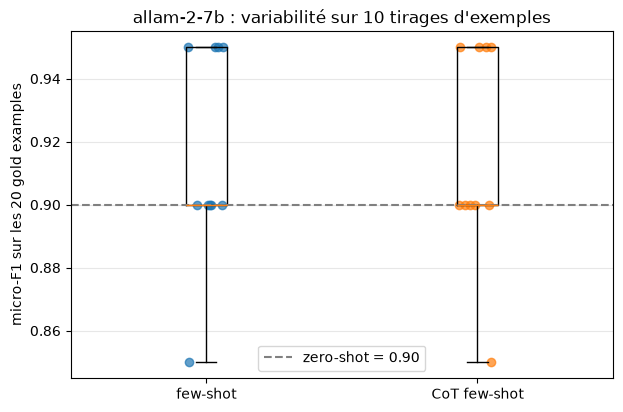

In [40]:
zero_shot_petit = scores[("allam-2-7b", "zero-shot")]
plt.figure(figsize=(7, 4.5))
plt.boxplot([few_shot_performance, cot_few_shot_performance], tick_labels=["few-shot", "CoT few-shot"])
rng = np.random.default_rng(0)
for i, perf in enumerate([few_shot_performance, cot_few_shot_performance], start=1):
    plt.scatter(i + rng.uniform(-0.07, 0.07, len(perf)), perf, alpha=0.7)
plt.axhline(zero_shot_petit, color="gray", linestyle="--", label=f"zero-shot = {zero_shot_petit:.2f}")
plt.ylabel("micro-F1 sur les 20 gold examples")
plt.title("allam-2-7b : variabilité sur 10 tirages d'exemples")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

In [41]:
print("Appels distincts enregistrés dans le cache :", len(cache))

Appels distincts enregistrés dans le cache : 520


## Analyse des résultats

### 1. Évaluation unique : même score partout, mais pas les mêmes erreurs

| micro-F1 (20 gold) | zero-shot | few-shot | CoT few-shot |
|---|---|---|---|
| `allam-2-7b` (7 milliards de paramètres) | 0.90 | 0.90 | 0.90 |
| `qwen3.8-27b` (27 milliards) | 0.90 | 0.90 | 0.90 |

Les six combinaisons font **2 erreurs sur 20**, mais ce ne sont pas toujours les mêmes. Au total, 4 critiques sont concernées :

| Critique (vérité) | Ce qui la rend difficile | Qui se trompe |
|---|---|---|
| « THE greatest Mob/Crime film... *and I have the brain capacity of an earth worm* » (negative) | **sarcasme** : tous les mots sont positifs, seule la dernière phrase révèle l'ironie | **les 6 combinaisons** |
| « I gave it an 8 only because it had received such low votes... really about a 5.5 » (positive) | avis **mitigé**, étiquette discutable | allam zero-shot, qwen few-shot et CoT |
| « his least successful film... still, it's almost worth seeing » (negative) | critique **nuancée** | allam few-shot et CoT : réponse `mixed` |
| « the stupidest movie... If you want a laugh, rent this » (negative) | le film est conseillé **pour en rire** | qwen zero-shot |

- **Le sarcasme met en échec les deux modèles**, quel que soit le prompt. Un lecteur humain comprend l'ironie grâce à la dernière phrase ; le modèle se fie à l'accumulation de mots positifs.
- **Le few-shot a changé le comportement du petit modèle, mais pas dans le bon sens.** Avec les 8 exemples, `allam-2-7b` a répondu **`mixed`** à la critique nuancée, une étiquette qui n'existe pas dans la consigne (« Answer only 'positive' or 'negative' »). La fonction d'évaluation la classe donc `unknown`, ce qui compte comme une erreur. En zero-shot, ce même modèle respectait le format et classait correctement cette critique.
- Les autres critiques mal classées sont **ambiguës**, et leur étiquette IMDB est discutable (une note de « 8, mais en réalité 5.5 » étiquetée *positive*).

### 2. Évaluations répétées : la variabilité due aux exemples

Sur 10 tirages d'exemples (petit modèle) :

| Prompt | micro-F1 moyen | écart-type | min – max |
|---|---|---|---|
| zero-shot (sans exemples, une seule valeur) | 0.90 | — | — |
| few-shot | **0.915** | 0.032 | 0.85 – 0.95 |
| CoT few-shot | **0.915** | 0.032 | 0.85 – 0.95 |

- Comme le prévoit le PDF, le score **dépend des exemples tirés** : selon le tirage, le few-shot fait de 1 à 3 erreurs (0.95 à 0.85). Une seule évaluation peut donc donner une fausse impression ; il faut répéter et regarder la moyenne et l'écart-type.
- Le few-shot et le CoT ont la **même moyenne**, mais pas les mêmes scores à chaque tirage (ils diffèrent aux répétitions 7 et 10). Cela confirme que le prompt CoT est réellement évalué, contrairement à la boucle du PDF où il recevait le score few-shot.
- Le gain moyen du few-shot sur le zero-shot (+0.015) est **plus petit que l'écart-type** (0.032). Avec 20 critiques gold, une critique vaut 0.05 point de F1 : cette évaluation ne permet pas de dire qu'un prompt est meilleur que l'autre.

### 3. Le coût en tokens

Le prompt zero-shot fait environ **49 tokens**, le few-shot **663** et le CoT **720** (sans la critique à classer). Chaque appel few-shot coûte donc environ 13 fois plus de tokens d'entrée que le zero-shot, pour un gain qui n'est pas mesurable ici. Ce coût est aussi la raison de la limite de 80 mots par critique : avec le quota gratuit de Groq (6 000 tokens par minute pour `allam-2-7b`), les 520 appels de l'évaluation ont pris plus d'une heure.

### 4. Ce que je retiens
- Sur des critiques courtes, même un modèle de 7 milliards de paramètres classe déjà 90 % des critiques en **zero-shot**. Le few-shot et le CoT n'apportent pas de gain mesurable, et le few-shot a même fait sortir le petit modèle du format demandé (`mixed`).
- Les erreurs restantes viennent surtout des **données** (sarcasme, avis mitigés, étiquettes discutables), pas du prompt. Un meilleur prompt ne corrige pas une étiquette ambiguë.
- Pour comparer réellement des prompts, il faudrait **beaucoup plus de critiques gold** (par exemple 200, pour qu'une erreur pèse 0.005 au lieu de 0.05), des critiques plus longues et plus nuancées, et vérifier le respect du format (le taux de `unknown`) en plus du F1.

### Écarts par rapport au PDF
- LLM : Groq (`allam-2-7b` et `qwen/qwen3.8-27b`) au lieu d'OpenAI `gpt-5.2`.
- Données : `dataset_imdb.zip` (50 000 critiques) au lieu de `load_dataset("imdb")` (25 000), et seulement les critiques de 80 mots au plus. Ce filtre déséquilibre un peu les classes (2 352 positives contre 1 865 négatives), car les critiques courtes sont plus souvent positives.
- `create_examples` reçoit un `random_state` pour que chaque tirage soit reproductible.
- La boucle des évaluations répétées évalue réellement le prompt CoT (correction de la dernière ligne du PDF).